In [2]:
import pandas as pd
import numpy as np


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

In [4]:
df = pd.read_csv('house_price_data.csv')
df.head()


,area_sqft,bedrooms,bathrooms,property_age_years,distance_to_city_km,school_rating,parking_spaces,near_metro,price_lakhs
0,1510,2,4,27,20.7,4.2,2,0,70.284303
1,1944,4,3,20,8.3,8.6,1,1,124.496508
2,1780,4,2,12,26.3,8.0,3,0,130.869260
3,1745,3,4,26,5.9,3.6,1,0,99.543781
4,2288,3,2,35,2.6,6.2,2,1,141.076534


In [4]:
df.shape

(1600, 9)

In [5]:
df['parking_spaces'].info()

<class 'pandas.Series'>
RangeIndex: 1600 entries, 0 to 1599
Series name: parking_spaces
Non-Null Count  Dtype
--------------  -----
1600 non-null   int64
dtypes: int64(1)
memory usage: 12.6 KB


In [6]:
df['parking_spaces'].unique(), df['near_metro'].unique()

(array([2, 1, 3, 0]), array([0, 1]))

In [7]:
df.sort_values('price_lakhs', ascending=False, inplace=True)

/tmp/ipykernel_24615/864175855.py:1: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.sort_values('price_lakhs', ascending=False, inplace=True)


In [8]:
df

,area_sqft,bedrooms,bathrooms,property_age_years,distance_to_city_km,school_rating,parking_spaces,near_metro,price_lakhs
1507,3189,4,4,8,2.8,6.0,2,0,212.027479
814,3047,3,3,4,24.2,9.6,3,1,208.283592
198,3161,1,3,14,6.2,7.2,3,1,204.949984
939,2986,1,4,11,2.6,9.5,2,1,204.134900
1140,2825,3,2,3,8.8,3.7,3,1,201.970727
...,...,...,...,...,...,...,...,...,...
746,697,3,4,26,26.2,4.7,1,0,30.880072
195,1258,3,1,23,28.7,3.1,0,0,29.621202
827,653,3,4,3,21.3,3.5,0,0,29.391397
360,654,2,1,28,23.5,3.9,0,0,22.258910


In [9]:
df.corr()

,area_sqft,bedrooms,bathrooms,property_age_years,distance_to_city_km,school_rating,parking_spaces,near_metro,price_lakhs
area_sqft,1.000000,-0.032230,-0.014122,-0.012682,-0.048161,-0.005124,-0.011388,0.007271,0.887064
bedrooms,-0.032230,1.000000,0.051974,-0.039624,-0.001658,0.017179,0.012068,0.015921,0.104265
bathrooms,-0.014122,0.051974,1.000000,-0.023533,0.020215,-0.020430,-0.006827,-0.020061,0.044376
property_age_years,-0.012682,-0.039624,-0.023533,1.000000,-0.042962,-0.038763,0.025200,0.035917,-0.145575
distance_to_city_km,-0.048161,-0.001658,0.020215,-0.042962,1.000000,0.019525,0.001963,0.002203,-0.272662
school_rating,-0.005124,0.017179,-0.020430,-0.038763,0.019525,1.000000,-0.040661,0.008293,0.103742
parking_spaces,-0.011388,0.012068,-0.006827,0.025200,0.001963,-0.040661,1.000000,0.053857,0.075072
near_metro,0.007271,0.015921,-0.020061,0.035917,0.002203,0.008293,0.053857,1.000000,0.113930
price_lakhs,0.887064,0.104265,0.044376,-0.145575,-0.272662,0.103742,0.075072,0.113930,1.000000


In [5]:
from sklearn.model_selection import train_test_split
X = df[['area_sqft','bedrooms','bathrooms','property_age_years','distance_to_city_km','school_rating','parking_spaces','near_metro']]
y = df['price_lakhs']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [6]:
from sklearn.tree import DecisionTreeRegressor

# Creating model
dt_model = DecisionTreeRegressor(
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42)
# Tain model
dt_model.fit(X_train,y_train)

# Predictions
dt_pred = dt_model.predict(X_test)
print("Decision Tree Predictions")
print(dt_pred[:10])



Decision Tree Predictions
[187.07850604  93.77499796  77.15425298 149.34283562 103.3310282
  57.2809814   67.18272784 171.5196996  133.99604143 158.21933308]


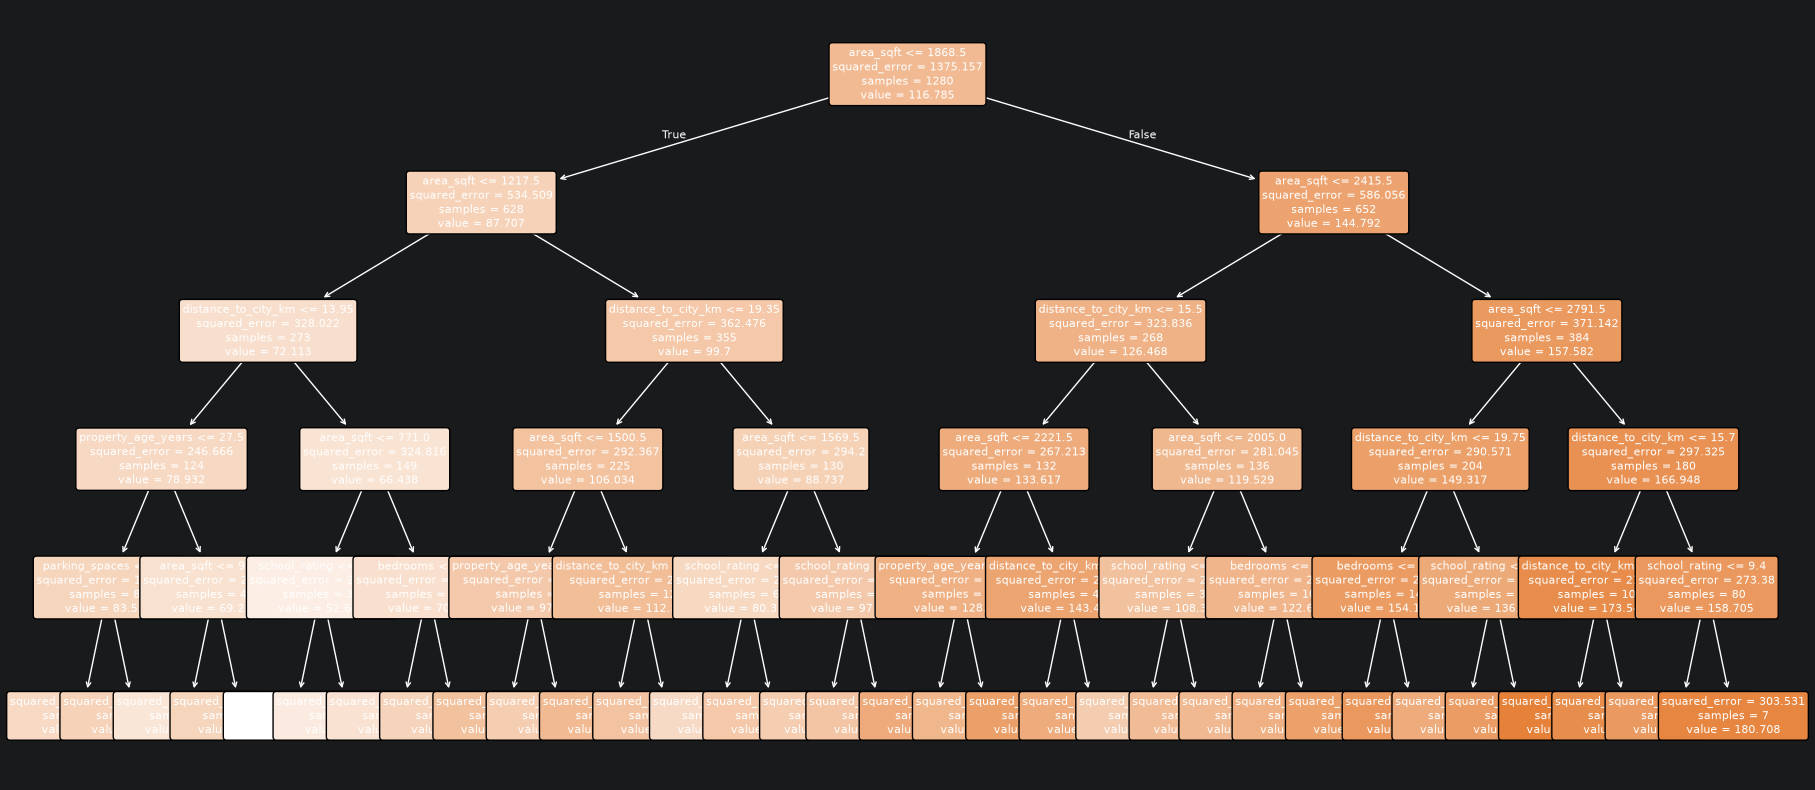

In [7]:
import  matplotlib.pyplot as plt

from sklearn.tree import plot_tree

plt.figure(figsize=(22, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.show()

In [8]:

from sklearn.ensemble import RandomForestRegressor

# Create model
rf_model = RandomForestRegressor(
    n_estimators=110,
    criterion='squared_error',
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=4,

)

# Train model
rf_model.fit(X_train, y_train)

# Predictions
rf_pred = rf_model.predict(X_test)

print("Random Forest Predictions:")
print(rf_pred[:10])


Random Forest Predictions:
[177.24161891  94.63236495  85.02754795 144.28768562 113.5433328
  62.857678    71.64125726 156.19912429 132.02631414 154.31294173]


In [9]:

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

models = {
    'Decision Tree': dt_pred,
    'Random Forest': rf_pred
}

results = []

for name, predictions in models.items():

    results.append({
        'Model': name,
        'R2 Score': r2_score(y_test, predictions),
        'RMSE': np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        'MAE': mean_absolute_error(
            y_test, predictions
        )
    })

results_df = pd.DataFrame(results)

print(results_df.round(3))


           Model  R2 Score    RMSE     MAE
0  Decision Tree     0.829  15.658  12.272
1  Random Forest     0.887  12.747   9.967


In [10]:

# Decision Tree feature importance
dt_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': dt_model.feature_importances_
})

# Random Forest feature importance
rf_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

print("Decision Tree Importance")
print(dt_importance.sort_values(
    by='Importance', ascending=False
))

print("\nRandom Forest Importance")
print(rf_importance.sort_values(
    by='Importance', ascending=False
))



Decision Tree Importance
               Feature  Importance
0            area_sqft    0.917361
4  distance_to_city_km    0.052774
5        school_rating    0.012147
3   property_age_years    0.008774
1             bedrooms    0.007778
6       parking_spaces    0.001165
2            bathrooms    0.000000
7           near_metro    0.000000

Random Forest Importance
               Feature  Importance
0            area_sqft    0.854117
4  distance_to_city_km    0.066945
3   property_age_years    0.025136
5        school_rating    0.019274
1             bedrooms    0.015116
6       parking_spaces    0.007110
7           near_metro    0.007058
2            bathrooms    0.005244


In [11]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

param_grid = {
    'n_estimators': [50, 70, 100, 200],
    'max_depth': [3, 4, 5, 8, 12, None],
    'min_samples_split': [2, 5, 10, 12],
    'min_samples_leaf': [1, 2, 3, 4]
}

grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameters:")
print(grid.best_params_)

print("Best CV R2:")
print(grid.best_score_)

best_rf = grid.best_estimator_

best_pred = best_rf.predict(X_test)

print("Test R2:", r2_score(y_test, best_pred))

Best Parameters:
{'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Best CV R2:
0.8771285769322935
Test R2: 0.8930216908318549


In [12]:
!pip install scikit-optimize

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 794.2/794.2 kB 7.4 MB/s eta 0:00:00

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [ ]:
from skopt import BayesSearchCV
from skopt.space import Categorical, Integer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# Define the search space for Bayesian Optimization
# Note: max_depth is treated categorically to handle 'None' as an option
search_space = {
    'n_estimators': Integer(50, 200),
    'max_depth': Categorical([3, 4, 5, 8, 12, None]),
    'min_samples_split': Integer(2, 12),
    'min_samples_leaf': Integer(1, 4)
}

# Initialize BayesSearchCV
bayes_search = BayesSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    search_spaces=search_space,
    n_iter=32,          # Number of parameter settings that are sampled
    cv=5,
    scoring='r2',
    n_jobs=-1,
    random_state=42
)

# Run the search
bayes_search.fit(X_train, y_train)

print("Best Parameters Found by Bayesian Search:")
print(bayes_search.best_params_)

print("\nBest CV R2 Score:")
print(bayes_search.best_score_)

# Evaluate on the test set
best_bayes_rf = bayes_search.best_estimator_
bayes_pred = best_bayes_rf.predict(X_test)
print("\nTest R2 Score:", r2_score(y_test, bayes_pred))